# Phase 6: Model Tuning and Explanation

In Phase 5, Stacking was my best model with ROC-AUC 0.796, and XGBoost was second with 0.792.

In this notebook I try to make my model better and understand how it works.

What I do in this notebook:
- Tune XGBoost by trying many different settings to find the best ones
- Check if Stacking gets better with the tuned XGBoost
- Choose a better cut-off than 0.5, so the model catches more customers who will churn
- Find out which features are most important for churn
- Use SHAP to see if each feature pushes customers towards churn or towards staying

At the end I save my final model so I can use it in the Streamlit app.

# Importing all required packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
import shap

from sklearn.model_selection import (train_test_split, cross_val_score,
                                     cross_val_predict, RandomizedSearchCV)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)

# Loading the data

In [2]:
churn = pd.read_parquet("../data/processed/churn_train.parquet")
print(churn.shape)

(5256, 14)


# Separating X and Y variables

In [3]:
X = churn.drop(columns=['Customer ID', 'Churn'])

In [4]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 5256 entries, 0 to 5255
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Frequency             5256 non-null   int64  
 1   Monetary              5256 non-null   float64
 2   AvgOrderValue         5256 non-null   float64
 3   AvgBasketSize         5256 non-null   float64
 4   Recency               5256 non-null   int64  
 5   Tenure                5256 non-null   int64  
 6   AvgDaysBetweenOrders  5256 non-null   float64
 7   IsOneTimeBuyer        5256 non-null   int64  
 8   Orders_Last90         5256 non-null   int64  
 9   UniqueProducts        5256 non-null   int64  
 10  Q4_Share              5256 non-null   float64
 11  IsUK                  5256 non-null   int64  
dtypes: float64(5), int64(7)
memory usage: 492.9 KB


In [5]:
y = churn['Churn']

In [6]:
y.info()

<class 'pandas.Series'>
RangeIndex: 5256 entries, 0 to 5255
Series name: Churn
Non-Null Count  Dtype
--------------  -----
5256 non-null   int64
dtypes: int64(1)
memory usage: 41.2 KB


# Splitting into training and test data

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [8]:
print(X_train.shape, X_test.shape)

(4204, 12) (1052, 12)


In [9]:
print(y_train.mean() , y_test.mean())

0.5647002854424358 0.564638783269962


## Function to evaluate models
- Instead of copying the same metric code for every model, I write a function that does it once.
- It gives back all the scores for a model as one row, so I can put all models in one table and compare them.
- It also gives the ROC-AUC on the training data, so I can check if a model is overfitting.

In [10]:
def evaluate(name, model):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    train_prob = model.predict_proba(X_train)[:, 1]

    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC_AUC': roc_auc_score(y_test, y_prob),
        'Train_ROC_AUC': roc_auc_score(y_train, train_prob),
    }

In [11]:
stack = joblib.load("../models/stacking.pkl")
xgb = joblib.load("../models/xgboost.pkl")

In [12]:
results = []
results.append(evaluate('Stacking (Phase 5)', stack))
results.append(evaluate('XGBoost (Phase 5)', xgb))
pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Train_ROC_AUC
0,Stacking (Phase 5),0.736,0.756,0.786,0.771,0.796,0.891
1,XGBoost (Phase 5),0.722,0.740,0.785,0.761,0.792,0.874


### Insights:
- I loaded the Stacking and XGBoost models I saved in Phase 5, and they give the same scores (0.796 and 0.792), so they loaded correctly.
- These are my starting scores. In this notebook I will try to improve them.

## Tune XGBoost with RandomizedSearchCV

## Tuning XGBoost
- In Phase 5 I chose the XGBoost settings myself. These settings are called hyperparameters.
- Now I let RandomizedSearchCV try 30 random combinations of settings, and test each one with 5-fold cross-validation.
- It keeps the combination with the best ROC-AUC. The test data is not used, so the final test is still fair.

In [13]:
param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4, 5],
    'min_child_weight': [1, 3, 5, 10],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
}

In [14]:
search = RandomizedSearchCV(
    XGBClassifier(random_state=42, eval_metric='logloss'),
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
)

In [15]:
search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.6, 0.8, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [2, 3, ...], 'min_child_weight': [1, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance

In [16]:
print(search.best_params_)
print(round(search.best_score_, 3))

{'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
0.809


In [17]:
top5 = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
top5[['params', 'mean_test_score', 'std_test_score']].head().round(3)

,params,mean_test_score,std_test_score
11,"{'subsample': 0.8, 'n_estimators': 200, 'min_c...",0.809,0.006
15,"{'subsample': 1.0, 'n_estimators': 200, 'min_c...",0.809,0.008
28,"{'subsample': 0.6, 'n_estimators': 500, 'min_c...",0.809,0.008
0,"{'subsample': 1.0, 'n_estimators': 300, 'min_c...",0.809,0.007
19,"{'subsample': 0.6, 'n_estimators': 200, 'min_c...",0.809,0.007


In [18]:
xgb_tuned = search.best_estimator_
results.append(evaluate('XGBoost (tuned)', xgb_tuned))
pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Train_ROC_AUC
0,Stacking (Phase 5),0.736,0.756,0.786,0.771,0.796,0.891
1,XGBoost (Phase 5),0.722,0.740,0.785,0.761,0.792,0.874
2,XGBoost (tuned),0.740,0.749,0.810,0.778,0.797,0.866


### Insights:
- The best settings were max_depth 5, learning_rate 0.01, n_estimators 200, subsample 0.8 and colsample_bytree 1.0.
- The tuned XGBoost has cross-validation ROC-AUC 0.809, a little better than before tuning (0.805).
- On the test set it improved on every main metric: ROC-AUC went from 0.792 to 0.797, accuracy from 0.722 to 0.740, recall from 0.785 to 0.810 and F1 from 0.761 to 0.778.
- It is now slightly better than Stacking (0.796), and it catches the most churners of all my models (recall 0.810).
- The top 5 combinations all scored 0.809, so many settings give almost the same result. This means the model is close to the best this data can give.
- Its train ROC-AUC (0.866) is closer to the test score than before, so it overfits less.

## Stacking with the tuned XGBoost
- My Phase 5 Stacking used the old XGBoost. I rebuild it with the tuned XGBoost to see if it gets better.
- If it is not clearly better than the tuned XGBoost alone, I will choose the tuned XGBoost because it is simpler.

In [19]:
log_reg = joblib.load("../models/log_reg_baseline.pkl")
rf = joblib.load("../models/random_forest.pkl")

In [20]:
stack_tuned = StackingClassifier(
    estimators=[
        ('lr', log_reg),
        ('rf', rf),
        ('xgb', xgb_tuned),
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
    n_jobs=-1,
)
stack_tuned.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('lr', ...), ('rf', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...max_iter=1000)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[Pipeline(step..._iter=1000))]), RandomForestC...ndom_state=42), XGBClassifier...ree=None, ...)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded::

In [21]:
results.append(evaluate('Stacking (tuned XGBoost)', stack_tuned))
pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Train_ROC_AUC
0,Stacking (Phase 5),0.736,0.756,0.786,0.771,0.796,0.891
1,XGBoost (Phase 5),0.722,0.740,0.785,0.761,0.792,0.874
2,XGBoost (tuned),0.740,0.749,0.810,0.778,0.797,0.866
3,Stacking (tuned XGBoost),0.741,0.763,0.786,0.774,0.797,0.884


### Insights:
- Stacking with the tuned XGBoost has ROC-AUC 0.797, exactly the same as the tuned XGBoost alone.
- It has slightly better precision (0.763 vs 0.749), but lower recall (0.786 vs 0.810), so it misses more churners.
- It is also more complex (4 models instead of 1) and overfits a little more (train 0.884 vs 0.866).
- So I choose the tuned XGBoost as my final model, because it gives the same ROC-AUC, catches more churners and is simpler. It will also be easier to explain with SHAP.

### Choose a better cut-off (threshold)
- The model gives a churn probability, and by default it uses 0.5 as the cut-off between churn and stay.
- A lower cut-off catches more churners (higher recall) but gives more false alarms (lower precision).
- Missing a churner costs more for the business, so I look for a cut-off that improves recall.
- I choose the cut-off using cross-validation predictions on the training data, so the test set stays fair.

In [22]:
train_probs = cross_val_predict(xgb_tuned, X_train, y_train, cv=5, method='predict_proba')[:, 1] #Getting cross-validation probabilities for the training customers

In [23]:
rows = []
for t in np.arange(0.30, 0.71, 0.05):
    pred = (train_probs >= t).astype(int)
    rows.append({
        'Threshold': round(t, 2),
        'Precision': precision_score(y_train, pred),
        'Recall': recall_score(y_train, pred),
        'F1': f1_score(y_train, pred),
    })

thresholds = pd.DataFrame(rows).round(3)
thresholds

,Threshold,Precision,Recall,F1
0,0.30,0.659,0.959,0.781
1,0.35,0.679,0.939,0.788
2,0.40,0.694,0.912,0.788
3,0.45,0.717,0.866,0.785
4,0.50,0.741,0.818,0.777
5,0.55,0.766,0.769,0.767
6,0.60,0.787,0.720,0.752
7,0.65,0.804,0.653,0.721
8,0.70,0.835,0.540,0.655


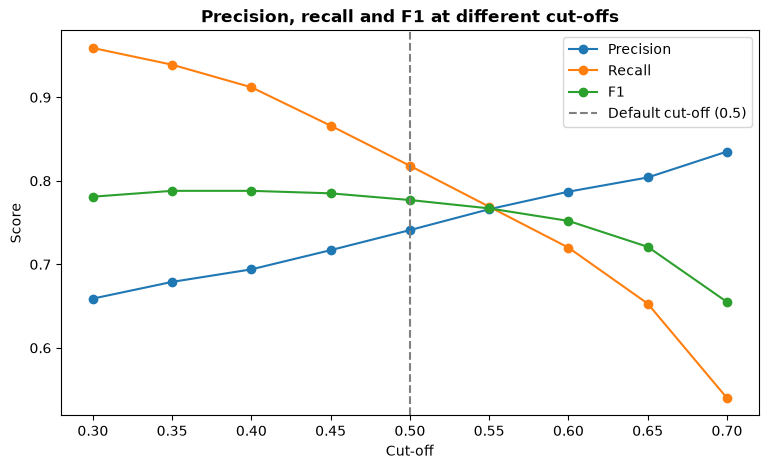

In [24]:
plt.figure(figsize=(9, 5))
plt.plot(thresholds['Threshold'], thresholds['Precision'], marker='o', label='Precision')
plt.plot(thresholds['Threshold'], thresholds['Recall'], marker='o', label='Recall')
plt.plot(thresholds['Threshold'], thresholds['F1'], marker='o', label='F1')
plt.axvline(0.5, color='grey', linestyle='--', label='Default cut-off (0.5)')
plt.title('Precision, recall and F1 at different cut-offs', fontweight='bold')
plt.xlabel('Cut-off')
plt.ylabel('Score')
plt.legend()
plt.show()

### Insights:
- At the default cut-off of 0.5, recall is 0.818 and precision is 0.741.
- When I lower the cut-off, recall goes up but precision goes down. When I raise it, the opposite happens.
- I chose a cut-off of 0.45. Recall goes up to 0.866, so I catch more churners, while precision is still 0.717 and F1 is a little better (0.785 vs 0.777).
- 0.40 would catch even more churners (recall 0.912), but precision would drop below 0.70, so too many customers would get offers they don't need.
- For the business, sending a few extra offers is cheaper than losing customers, so this trade-off is worth it.

## Final check on the test set
- I chose the cut-off 0.45 using the training data only.
- Now I check it on the test set and compare it with the default cut-off of 0.5.

In [25]:
THRESHOLD = 0.45

In [26]:
test_probs = xgb_tuned.predict_proba(X_test)[:, 1]
pred_default = (test_probs >= 0.5).astype(int)
pred_new = (test_probs >= THRESHOLD).astype(int)

In [27]:
final = pd.DataFrame([
    {'Cut-off': 0.5,
     'Accuracy': accuracy_score(y_test, pred_default),
     'Precision': precision_score(y_test, pred_default),
     'Recall': recall_score(y_test, pred_default),
     'F1': f1_score(y_test, pred_default)},
    {'Cut-off': THRESHOLD,
     'Accuracy': accuracy_score(y_test, pred_new),
     'Precision': precision_score(y_test, pred_new),
     'Recall': recall_score(y_test, pred_new),
     'F1': f1_score(y_test, pred_new)},
])
final.round(3)

,Cut-off,Accuracy,Precision,Recall,F1
0,0.50,0.740,0.749,0.81,0.778
1,0.45,0.735,0.719,0.87,0.788


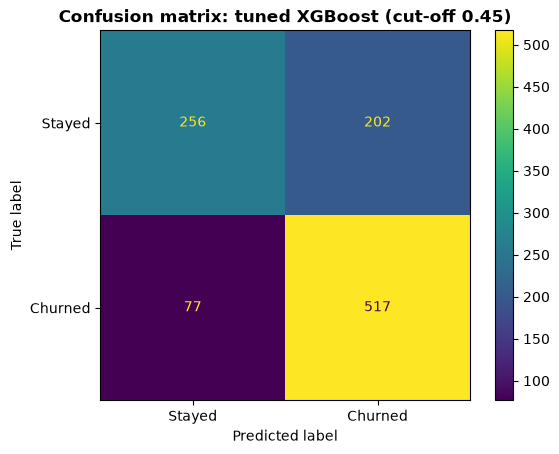

In [28]:
ConfusionMatrixDisplay.from_predictions(y_test, pred_new,
                                        display_labels=['Stayed', 'Churned'])
plt.title('Confusion matrix: tuned XGBoost (cut-off 0.45)', fontweight='bold')
plt.show()

### Insights:
- On the test set, the cut-off 0.45 raised recall from 0.810 to 0.870, and precision went from 0.749 to 0.719.
- With the new cut-off, the model missed only 77 churners, compared with 122 for Logistic Regression in Phase 4. So 45 more customers can be contacted before they leave.
- The cost is more false alarms: 202 customers got flagged but stayed. For the business, sending them an offer is cheaper than losing real churners.
- The test results (recall 0.870, precision 0.719) are almost the same as on the training data (0.866 and 0.717), so the cut-off works on new customers too.

## Which features matter most
- I use permutation importance: I shuffle one feature at a time and see how much the ROC-AUC drops.
- A big drop means the model depends a lot on that feature. A drop near 0 means it is not important.

In [29]:
perm = permutation_importance(xgb_tuned, X_test, y_test,
                              scoring='roc_auc', n_repeats=10, random_state=42)

In [30]:
importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm.importances_mean,
    'Std': perm.importances_std,
}).sort_values('Importance', ascending=False)

importance.round(4)

,Feature,Importance,Std
4,Recency,0.1631,0.0118
6,AvgDaysBetweenOrders,0.0285,0.0045
1,Monetary,0.0094,0.0042
10,Q4_Share,0.0088,0.0029
9,UniqueProducts,0.0076,0.0032
5,Tenure,0.0033,0.0009
0,Frequency,0.0016,0.0009
8,Orders_Last90,0.0015,0.0004
2,AvgOrderValue,0.0012,0.0010
7,IsOneTimeBuyer,0.0000,0.0000


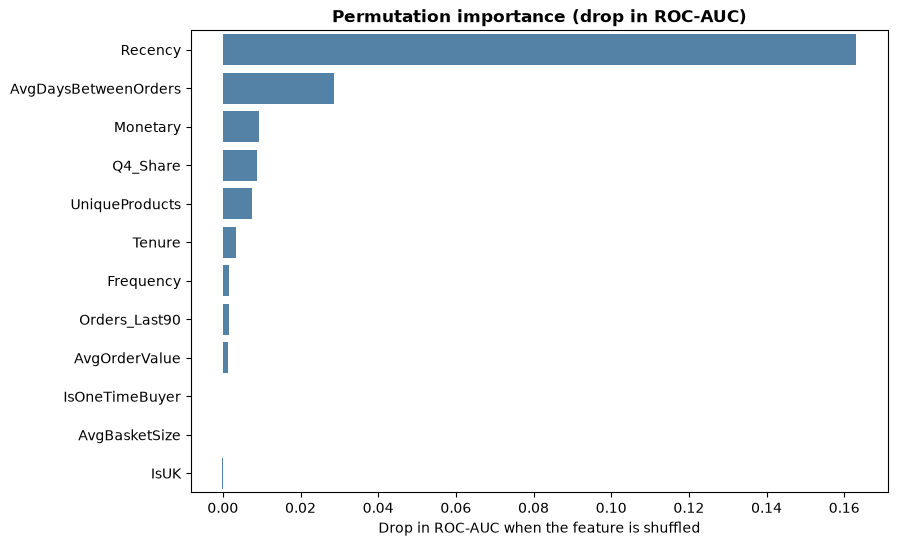

In [31]:
plt.figure(figsize=(9, 6))
sns.barplot(x='Importance', y='Feature', data=importance, color='steelblue')
plt.title('Permutation importance (drop in ROC-AUC)', fontweight='bold')
plt.xlabel('Drop in ROC-AUC when the feature is shuffled')
plt.ylabel('')
plt.show()

### Insights:
- Recency is by far the most important feature. Shuffling it drops ROC-AUC by 0.163, more than 5 times any other feature. How long ago a customer last bought is the strongest sign of churn.
- The next most important are AvgDaysBetweenOrders (0.029), Monetary (0.009), Q4_Share (0.009) and UniqueProducts (0.008).
- Q4_Share matters because my 90-day window is September to December. Customers who usually buy in Q4 are more likely to come back for Christmas.
- Frequency and Orders_Last90 have very small importance, even though they were strongly linked with churn in Phase 2. This is because they are highly correlated with Recency and other features, so when one is shuffled the model still gets the same information from the others.
- IsOneTimeBuyer, AvgBasketSize and IsUK are about 0, so the model does not use them.

## How each feature affects churn (SHAP)
- Permutation importance shows how much each feature matters, but not in which direction.
- SHAP shows for every customer how much each feature pushed the prediction towards churn or towards staying.

In [32]:
explainer = shap.TreeExplainer(xgb_tuned)
shap_values = explainer(X_test)

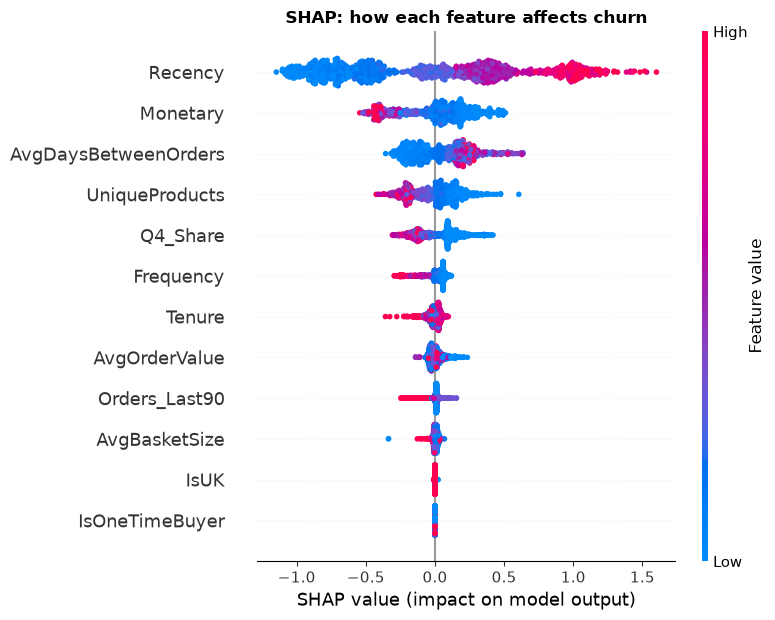

In [33]:
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title('SHAP: how each feature affects churn', fontweight='bold')
plt.tight_layout()
plt.show()

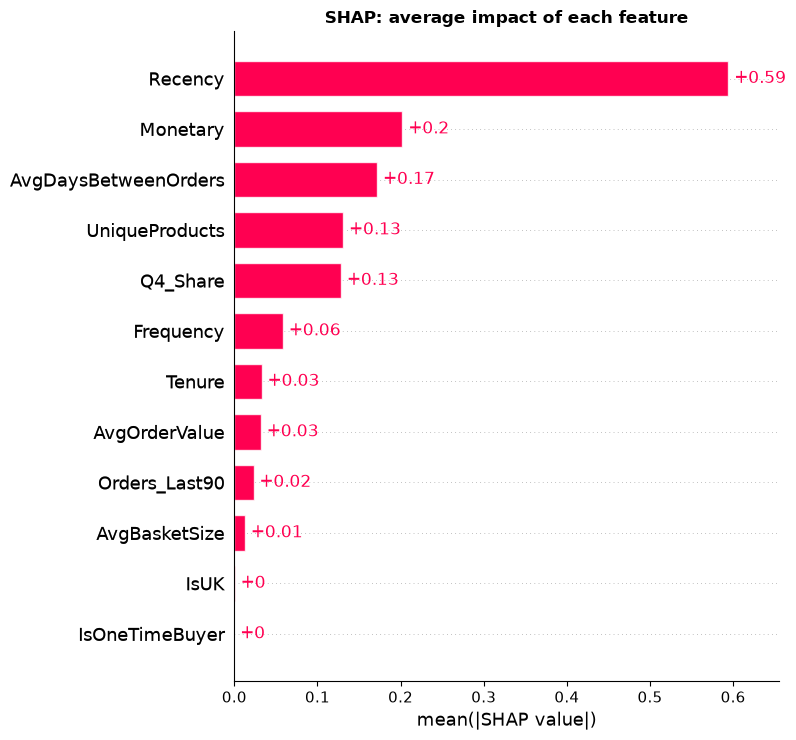

In [34]:
shap.plots.bar(shap_values, max_display=12, show=False)
plt.title('SHAP: average impact of each feature', fontweight='bold')
plt.tight_layout()
plt.show()

### Insights:
- Recency has the biggest effect. Customers who have not bought for a long time (red) are pushed strongly towards churn, and recent buyers (blue) towards staying.
- Customers who spent more (Monetary), bought more different products (UniqueProducts) and ordered more often (Frequency, Orders_Last90) are more likely to stay.
- Customers with long gaps between orders (AvgDaysBetweenOrders) are more likely to churn.
- Customers who usually buy in October to December (Q4_Share) are more likely to stay, because my 90-day window is the Christmas season.
- IsUK and IsOneTimeBuyer have no effect, which matches the permutation importance.
- This matches my RFM segments from Phase 1: customers who bought recently, often and spent a lot are the Champions, and customers who have not bought for a long time are At Risk or Lost.

### What the business can do
- Recency is the biggest warning sign. If a customer has not bought for a long time, the shop should contact them early, before they are lost.
- Customers who take a long time between orders can get reminders or small offers to buy again sooner.
- Customers who buy only a few products can be shown other products, because customers who buy many different products stay longer.
- Many customers come back for Christmas, so the shop should try to win customers back before October to December.

## Saving the final model
- My final model is the tuned XGBoost with a cut-off of 0.45.
- I save the model and the cut-off together in one file, so the Streamlit app can use them.
- I also save the feature importance table to show it in the app.

### saving the model and the cut-off together

In [35]:
os.makedirs("../models", exist_ok=True)

final_model = {
    'model': xgb_tuned,
    'threshold': THRESHOLD,
}
joblib.dump(final_model, "../models/final_model.pkl")
print("Saved final model with cut-off", THRESHOLD)

Saved final model with cut-off 0.45


### saving the feature importance table

In [36]:
importance.to_csv("../models/feature_importance.csv", index=False)
print("Saved feature importance")

Saved feature importance


## Summary
- In this notebook I tried to improve my best model from Phase 5 and explain how it works.
- I tuned XGBoost with RandomizedSearchCV. The tuned XGBoost got cross-validation ROC-AUC 0.809 and test ROC-AUC 0.797, better than before tuning (0.805 and 0.792).
- I also tried Stacking with the tuned XGBoost, but it was not better (same ROC-AUC 0.797 and lower recall), so I chose the tuned XGBoost as my final model because it is simpler.
- I changed the cut-off from 0.5 to 0.45 to catch more churners. On the test set, recall went up from 0.810 to 0.870, and precision is still 0.719.
- My final model misses only 77 churners, compared with 122 for Logistic Regression in Phase 4.
- Recency is the most important feature by far. Customers who have not bought for a long time are the most likely to churn.
- Customers who spend more, buy more different products and order more often are more likely to stay.
- I saved the final model with its cut-off, and the feature importance table, for the Streamlit app.
- Next, in Phase 7, I will build the Streamlit app.